# Case Study - Comparing COVID Fatalities

In this notebook, you will compare COVID fatalities in Portugal and Colombia. The results may be counterintuitive and surprising! We will use data of COVID cases from both countries on May 28, 2020.

## Reading in the Data

First, we import Pandas.

In [1]:
import pandas as pd

from google.colab import _reprs
_reprs.disable_pandas_series_repr()

The Portugal and Colombia data live in separate files in the directory http://dlsun.github.io/pods/data/covid/.

In [2]:
url = "http://dlsun.github.io/pods/data/covid/"

Now let's read in the data.

In [3]:
df_PT = pd.read_csv(url + "portugal_2020-05-28.csv")
df_PT

,age,sex,fatality
0,60-69,Female,0
1,60-69,Male,0
2,80+,Male,0
3,60-69,Female,0
4,50-59,Female,0
...,...,...,...
31591,40-49,Male,0
31592,30-39,Male,0
31593,80+,Female,0
31594,40-49,Female,0


In [4]:
df_CO = pd.read_csv(url + "colombia_2020-05-28.csv")
df_CO

,Departamento,Edad,Sexo,Tipo,Ubicación,Estado,Fecha de inicio de síntomas,Fecha de muerte,Fecha de diagnóstico,Fecha recuperado
0,Bogotá D.C.,19,F,Importado,Recuperado,Leve,2020-02-27,- -,2020-03-06,2020-03-13
1,Valle del Cauca,34,M,Importado,Recuperado,Leve,2020-03-04,- -,2020-03-09,2020-03-19
2,Antioquia,50,F,Importado,Recuperado,Leve,2020-02-29,- -,2020-03-09,2020-03-15
3,Antioquia,55,M,Relacionado,Recuperado,Leve,2020-03-06,- -,2020-03-11,2020-03-26
4,Antioquia,25,M,Relacionado,Recuperado,Leve,2020-03-08,- -,2020-03-11,2020-03-23
...,...,...,...,...,...,...,...,...,...,...
25361,Buenaventura D.E.,48,M,En estudio,Hospital,Moderado,2020-05-12,- -,2020-05-28,NaN
25362,Valle del Cauca,55,F,En estudio,Casa,Leve,2020-05-21,/ /,2020-05-28,NaN
25363,Buenaventura D.E.,39,F,En estudio,Casa,Leve,2020-05-23,/ /,2020-05-28,NaN
25364,Valle del Cauca,13,F,En estudio,Casa,Leve,2020-05-13,/ /,2020-05-28,NaN


Notice that the Colombia data is more raw than the Portugal data. We need to clean the data to make it look like the Portugal data.

The section below performs the data cleaning. Run the cells below. You are not responsible for this information, but try to read the code and follow along.

## Cleaning the Colombia Data

### Transforming a Categorical Variable

Each row represents a case, but there is no column that corresponds directly to fatality. We will transform the "Estado" (state) column into a fatality column. If a patient died, then their state is marked as "Fallecido" (deceased).

The `Series.map(...)` function can be used to transform a categorical variable.

In [5]:
df_CO["Estado"].map({
    "Fallecido": 1
})

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
         ..
25361   NaN
25362   NaN
25363   NaN
25364   NaN
25365   NaN
Name: Estado, Length: 25366, dtype: float64

There are other Estados (states), such as Leve (mild) and Asintomático (asymptomatic). However, we did not specify their value, so they were replaced by the missing value `NaN`. We will fill these `NaN`s with 0s and store the result in a _new_ column called "fatality".

In [6]:
df_CO["fatality"] = df_CO["Estado"].map({
    "Fallecido": 1
}).fillna(0)

# Look for a new column called "fatality" in the DataFrame.
df_CO

,Departamento,Edad,Sexo,Tipo,Ubicación,Estado,Fecha de inicio de síntomas,Fecha de muerte,Fecha de diagnóstico,Fecha recuperado,fatality
0,Bogotá D.C.,19,F,Importado,Recuperado,Leve,2020-02-27,- -,2020-03-06,2020-03-13,0.0
1,Valle del Cauca,34,M,Importado,Recuperado,Leve,2020-03-04,- -,2020-03-09,2020-03-19,0.0
2,Antioquia,50,F,Importado,Recuperado,Leve,2020-02-29,- -,2020-03-09,2020-03-15,0.0
3,Antioquia,55,M,Relacionado,Recuperado,Leve,2020-03-06,- -,2020-03-11,2020-03-26,0.0
4,Antioquia,25,M,Relacionado,Recuperado,Leve,2020-03-08,- -,2020-03-11,2020-03-23,0.0
...,...,...,...,...,...,...,...,...,...,...,...
25361,Buenaventura D.E.,48,M,En estudio,Hospital,Moderado,2020-05-12,- -,2020-05-28,NaN,0.0
25362,Valle del Cauca,55,F,En estudio,Casa,Leve,2020-05-21,/ /,2020-05-28,NaN,0.0
25363,Buenaventura D.E.,39,F,En estudio,Casa,Leve,2020-05-23,/ /,2020-05-28,NaN,0.0
25364,Valle del Cauca,13,F,En estudio,Casa,Leve,2020-05-13,/ /,2020-05-28,NaN,0.0


### Transforming a Quantitative Variable Into a Categorical Variable

We also need to convert "Edad" (age), which is a quantitative variable in this data set, into age ranges, as in the Portugal data set. To do this, we use a function in Pandas called `pd.cut(...)`.

In [7]:
df_CO["age"] = pd.cut(
    df_CO["Edad"],
    bins=[0, 10, 20, 30, 40, 50, 60, 70, 80, 120],
    labels=["0-9", "10-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"],
    right=False)

df_CO

,Departamento,Edad,Sexo,Tipo,Ubicación,Estado,Fecha de inicio de síntomas,Fecha de muerte,Fecha de diagnóstico,Fecha recuperado,fatality,age
0,Bogotá D.C.,19,F,Importado,Recuperado,Leve,2020-02-27,- -,2020-03-06,2020-03-13,0.0,10-19
1,Valle del Cauca,34,M,Importado,Recuperado,Leve,2020-03-04,- -,2020-03-09,2020-03-19,0.0,30-39
2,Antioquia,50,F,Importado,Recuperado,Leve,2020-02-29,- -,2020-03-09,2020-03-15,0.0,50-59
3,Antioquia,55,M,Relacionado,Recuperado,Leve,2020-03-06,- -,2020-03-11,2020-03-26,0.0,50-59
4,Antioquia,25,M,Relacionado,Recuperado,Leve,2020-03-08,- -,2020-03-11,2020-03-23,0.0,20-29
...,...,...,...,...,...,...,...,...,...,...,...,...
25361,Buenaventura D.E.,48,M,En estudio,Hospital,Moderado,2020-05-12,- -,2020-05-28,NaN,0.0,40-49
25362,Valle del Cauca,55,F,En estudio,Casa,Leve,2020-05-21,/ /,2020-05-28,NaN,0.0,50-59
25363,Buenaventura D.E.,39,F,En estudio,Casa,Leve,2020-05-23,/ /,2020-05-28,NaN,0.0,30-39
25364,Valle del Cauca,13,F,En estudio,Casa,Leve,2020-05-13,/ /,2020-05-28,NaN,0.0,10-19


# Exercises

**Exercise 1.** Calculate the overall fatality rate for Portugal. That is, calculate the distribution of fatality. Do the same for Colombia. How do they compare?

In [10]:
# Portugal overall fatality rate
pt_fatality_rate = df_PT["fatality"].mean()
print(f"Portugal Overall Fatality Rate: {pt_fatality_rate:.4f} ({pt_fatality_rate * 100:.2f}%)")

Portugal Overall Fatality Rate: 0.0433 (4.33%)


In [11]:
# Colombia overall fatality rate
co_fatality_rate= df_CO["fatality"].mean()
print(f"Colombia Overall Fatality Rate: {co_fatality_rate:.4f} ({co_fatality_rate * 100:.2f}%)")

Colombia Overall Fatality Rate: 0.0324 (3.24%)


Portugal's overall fatality rate is approximately 4.33%, whereas Colombia's overall fatality rate is lower at approximately 3.24%.

At first glance, this comparison suggests that the COVID-19 situation in Portugal was overall more severe or fatal. However, to draw a meaningful conclusion, we must analyze the fatality rates stratified by age group to examine whether this overall comparison is influenced by Simpson's Paradox.

**Exercise 2a.** Calculate the fatality rates for each age group in Portugal. That is, calculate the conditional probabilities for each age group:
$$P(\text{fatality} = 1 | \text{age}).$$
Save the results in a `Series` called `fatality_rates_PT`.

In [25]:
# Portugal fatality rates by age
fatality_rates_PT = df_PT.groupby("age", observed=False)["fatality"].mean()
fatality_rates_PT

age
0-9      0.000000
10-19    0.000000
20-29    0.000243
30-39    0.000211
40-49    0.002822
50-59    0.007995
60-69    0.035017
70-79    0.106031
80+      0.205180
Name: fatality, dtype: float64

**Exercise 2b.** Calculate the fatality rate for each age group for Colombia. Save the results in a `Series` called `fatality_rates_CO`.

In [26]:
# Colombia fatality rates by age
fatality_rates_CO = df_CO.groupby("age", observed=False)["fatality"].mean()
fatality_rates_CO

age
0-9      0.004525
10-19    0.000513
20-29    0.002316
30-39    0.004274
40-49    0.015125
50-59    0.036823
60-69    0.097909
70-79    0.191585
80+      0.278832
Name: fatality, dtype: float64

**Exercise 3a.** Combine the Colombia and Portugal results into a single `DataFrame` for plotting.

_Learn:_

You can stack multiple Pandas objects into one `DataFrame` using the `pd.concat()` function. You can view the documentation for the `pd.concat()` function in a number of ways:

- typing `?pd.concat` in a cell and running it
- searching "pd.concat" on Google

(I do not recommend using ChatGPT because it can generate erroneous information.)

Read the documentation for `pd.concat()`. To combine our `DataFrame`s, we will use the `objs` argument and the `axis` argument. Which of these arguments are *required*, and which are *optional*? How do you know?

There are two potential values for the `axis` argument. What happens when you try each one? What if you don't specify either axis?

### Explanation of `pd.concat` Arguments:

* **`objs` (Required):** This argument is required because we must specify which pandas objects (such as Series or DataFrames) we want to join together. Without passing a sequence of objects, there is nothing to concatenate.
* **`axis` (Optional):** This parameter is optional and defaults to `0`. Specifying `axis=0` concatenates the objects vertically (stacking them on top of each other), whereas `axis=1` concatenates them horizontally (aligning them side-by-side by their index).

_Do:_

Now, apply what you learned above, and save the combined `DataFrame` to a variable called `fatality_rates_combined`.

In [27]:
# Combine the series side-by-side using axis=1
fatality_rates_combined = pd.concat([fatality_rates_CO, fatality_rates_PT], axis=1)
fatality_rates_combined.columns = ["Colombia", "Portugal"]
display(fatality_rates_combined)

,Colombia,Portugal
age,,
0-9,0.004525,0.000000
10-19,0.000513,0.000000
20-29,0.002316,0.000243
30-39,0.004274,0.000211
40-49,0.015125,0.002822
50-59,0.036823,0.007995
60-69,0.097909,0.035017
70-79,0.191585,0.106031
80+,0.278832,0.205180


*Optional*: If you wanted to to specify the names of the columns of your concatenated `DataFrame`, there's an argument for that! Read the documentation and try to figure out which argument it is, then use it to name the columns "Colombia" and "Portugal".

In [ ]:
fatality_rates_combined = pd.concat([fatality_rates_CO, fatality_rates_PT], axis=1)
fatality_rates_combined.columns = ["Colombia", "Portugal"]
display(fatality_rates_combined)

**Exercise 3b.** Make a bar plot comparing the fatality rates for each age group in Colombia and Portugal. Do you notice anything strange? (Hint: Take a look at your answer to Exercise 1.) Can you explain what is going on?



<Axes: xlabel='age'>

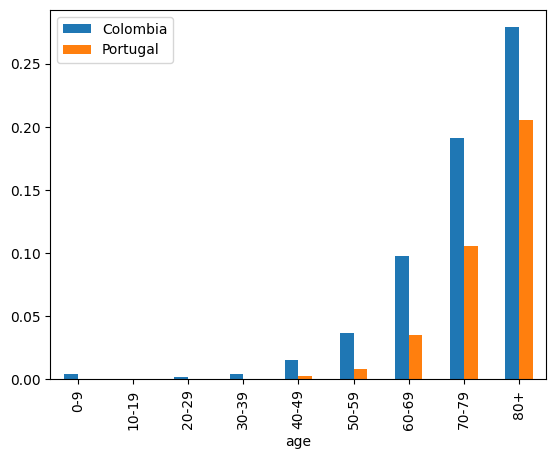

In [30]:
# YOUR CODE HERE
fatality_rates_combined.plot(kind="bar")

### Explanation of the Observation (Simpson's Paradox):

This counterintuitive result is a classic demonstration of **Simpson's Paradox**:

1. **The Paradox:** In Exercise 1, we observed that Portugal has a higher overall fatality rate than Colombia. However, when stratified by age group in Exercise 3b, Colombia exhibits a higher fatality rate across **every single age group**.
2. **The Cause:** This discrepancy is driven by the stark difference in the age distribution of COVID-19 cases between the two nations. Portugal has a significantly older population on average, and COVID-19 is much more lethal among older cohorts. Because a vast majority of Portugal's cases occurred in high-risk older age groups, its *aggregated* fatality rate is pulled upward. Conversely, Colombia's cases were predominantly concentrated among younger, lower-risk demographics, which lowers its overall average despite having higher fatality rates within each individual age bracket.